In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import scipy.cluster.hierarchy as sch

In [15]:
url = "https://raw.githubusercontent.com/stephanraabe/Mall-Customer-Segmentation/master/Mall_Customers.csv"
filename = "Mall_Customers.csv"

In [16]:
# 2. Inspect Dataset
print("Dataset Shape:", df.shape)
print("\nColumn Data Types & Missing Values:")
print(df.info())
print("\nSummary Statistics:")
print(df.describe())

Dataset Shape: (200, 3)

Column Data Types & Missing Values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Annual Income (k$)      200 non-null    float64
 1   Spending Score (1-100)  200 non-null    float64
 2   CustomerID              200 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 4.8 KB
None

Summary Statistics:
       Annual Income (k$)  Spending Score (1-100)  CustomerID
count          200.000000              200.000000  200.000000
mean            53.566617               50.231774  100.500000
std             26.858518               24.005880   57.879185
min             14.853771               13.705631    1.000000
25%             25.862943               25.705347   50.750000
50%             53.411807               52.164323  100.500000
75%             83.909486               74.430888  150.25000

In [17]:
# 3. Feature Selection
# Typically, Annual Income and Spending Score are chosen for behavioral segmentation
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].values

# 4. Feature Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [18]:
# Suboptimal random initialization example
kmeans_bad = KMeans(n_clusters=5, init='random', n_init=1, random_state=42)
kmeans_bad.fit(X_scaled)

# Optimal K-Means++ initialization
kmeans_good = KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=42)
kmeans_good.fit(X_scaled)

KMeans(n_clusters=5, n_init=10, random_state=42)

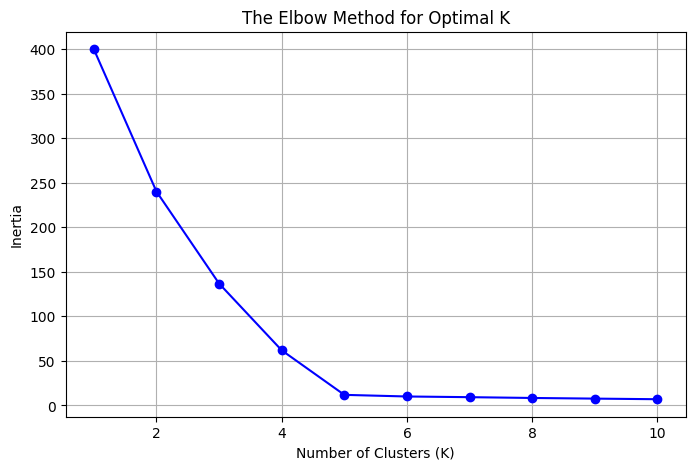

In [19]:
inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='-', color='b')
plt.title('The Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

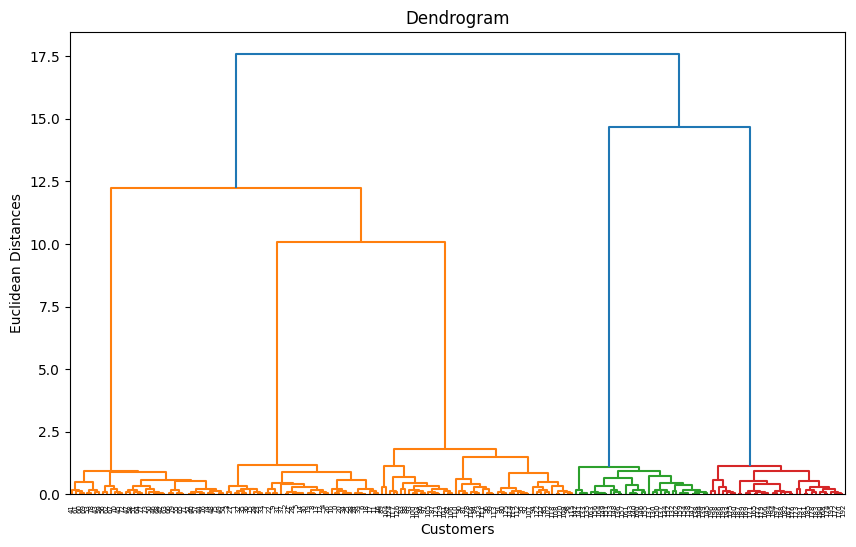

In [20]:
# Hierarchical Clustering

# Generate Dendrogram to determine cluster count
plt.figure(figsize=(10, 6))
dendrogram = sch.dendrogram(sch.linkage(X_scaled, method='ward'))
plt.title('Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Euclidean Distances')
plt.show()

# Apply Agglomerative Clustering
hc = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X_scaled)

In [21]:
# DBSCAN Clustering
# Apply DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=5)
y_dbscan = dbscan.fit_predict(X_scaled)

# Count noise points (labeled as -1)
n_noise = list(y_dbscan).count(-1)
print(f"Estimated number of noise points: {n_noise}")

Estimated number of noise points: 0


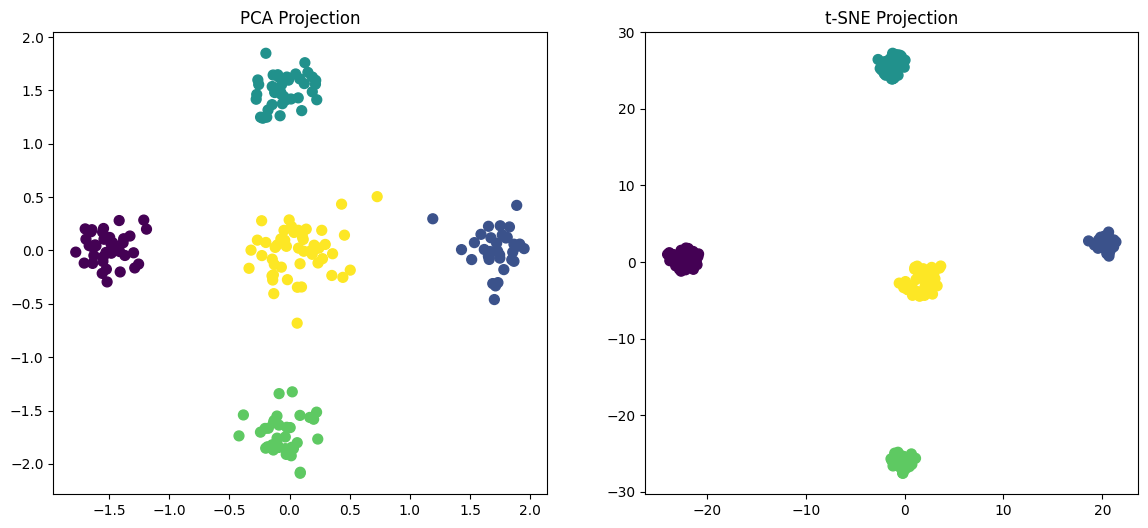

In [24]:
# Dimensionality Reduction
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# t-SNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

# Plotting comparisons
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_good.labels_, cmap='viridis', s=50)
axes[0].set_title('PCA Projection')
axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=kmeans_good.labels_, cmap='viridis', s=50)
axes[1].set_title('t-SNE Projection')
plt.show()

In [28]:
# Cluster Analysis
y_kmeans = kmeans_good.labels_
df['Cluster'] = y_kmeans

cluster_summary = df.groupby('Cluster').agg({
    'Annual Income (k$)': ['mean', 'median', 'min', 'max'],
    'Spending Score (1-100)': ['mean', 'median', 'min', 'max'],
    'CustomerID': 'count'
}).rename(columns={'CustomerID': 'Customer Count'})

print("\n--- Cluster Summary Profile ---")
display(cluster_summary)

print("\n--- Strategic Business Recommendations ---")
print("1. Target / Premium Segment (High Income, High Spending): Offer exclusive VIP club memberships and early access to luxury collections.")
print("2. Careless Spenders (Low Income, High Spending): Target with impulse-buy promos, fashion sales, and tailored credit card offers.")
print("3. Conservative / Prudent (High Income, Low Spending): Focus on product durability, quality, and investment value rather than flash discounts.")
print("4. Budget Shoppers (Low Income, Low Spending): Provide entry-level promotional bundles, clear savings alerts, and value deals.")
print("5. Standard / Moderate Segment (Medium Income, Medium Spending): Maintain engagement via balanced loyalty rewards and seasonal storewide discounts.")


--- Cluster Summary Profile ---


Annual Income (k$)                                   \
                      mean     median        min        max   
Cluster                                                       
0                24.662240  24.942683  17.568631  32.305167   
1                86.098055  86.256634  70.504612  94.539215   
2                24.329654  24.791176  14.853771  31.116265   
3                85.214797  85.339008  75.501650  94.793096   
4                55.153957  55.160411  43.907837  67.677907   

        Spending Score (1-100)                                  Customer Count  
                          mean     median        min        max          count  
Cluster                                                                         
0                    25.249740  25.695610  19.331831  34.540096             40  
1                    79.516793  79.733795  71.269998  89.357440             35  
2                    74.711084  74.203259  67.302179  82.173843             40  
3                    20.069827  19.045435  13.705631  28.390491             35  
4                    51.247801  52.164323  39.772567  71.102279             50


--- Strategic Business Recommendations ---
1. Target / Premium Segment (High Income, High Spending): Offer exclusive VIP club memberships and early access to luxury collections.
2. Careless Spenders (Low Income, High Spending): Target with impulse-buy promos, fashion sales, and tailored credit card offers.
3. Conservative / Prudent (High Income, Low Spending): Focus on product durability, quality, and investment value rather than flash discounts.
4. Budget Shoppers (Low Income, Low Spending): Provide entry-level promotional bundles, clear savings alerts, and value deals.
5. Standard / Moderate Segment (Medium Income, Medium Spending): Maintain engagement via balanced loyalty rewards and seasonal storewide discounts.
